In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Semantic Segmentation and the Dataset

When discussing object detection tasks
in that section to that section,
rectangular bounding boxes
are used to label and predict objects in images.
This section will discuss the problem of *semantic segmentation*,
which focuses on how to divide an image into regions belonging to different semantic classes.
Different from object detection,
semantic segmentation
recognizes and understands
what are in images in pixel level:
its labeling and prediction of semantic regions are
in pixel level.
the figure shows the labels
of the dog, cat, and background of the image in semantic segmentation.
Compared with in object detection,
the pixel-level borders labeled
in semantic segmentation are obviously more fine-grained.


![Labels of the dog, cat, and background of the image in semantic segmentation.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/segmentation.svg)


## Image Segmentation and Instance Segmentation

There are also two important tasks
in the field of computer vision that are similar to semantic segmentation,
namely image segmentation and instance segmentation.
We will briefly
distinguish them from semantic segmentation as follows.

* *Image segmentation* divides an image into several constituent regions. The methods for this type of problem usually make use of the correlation between pixels in the image. It does not need label information about image pixels during training, and it cannot guarantee that the segmented regions will have the semantics that we hope to obtain during prediction. Taking the image in the figure as input, image segmentation may divide the dog into two regions: one covers the mouth and eyes which are mainly black, and the other covers the rest of the body which is mainly yellow.
* *Instance segmentation* is also called *simultaneous detection and segmentation*. It studies how to recognize the pixel-level regions of each object instance in an image. Different from semantic segmentation, instance segmentation needs to distinguish not only semantics, but also different object instances. For example, if there are two dogs in the image, instance segmentation needs to distinguish which of the two dogs a pixel belongs to.


## The Pascal VOC2012 Semantic Segmentation Dataset

One of the most important semantic segmentation dataset
is [Pascal VOC2012](http://host.robots.ox.ac.uk/pascal/VOC/voc2012/).
In the following,
we will take a look at this dataset.

In [ ]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

In [ ]:
import os

The tar file of the dataset is about 2 GB,
so it may take a while to download the file.
The extracted dataset is located at `../data/VOCdevkit/VOC2012`.

In [2]:

d2l.DATA_HUB['voc2012'] = (d2l.DATA_URL + 'VOCtrainval_11-May-2012.tar',
                           '4e443f8a2eca6b1dac8a6c57641b67dd40621a49')

voc_dir = d2l.download_extract('voc2012', 'VOCdevkit/VOC2012')

After entering the path `../data/VOCdevkit/VOC2012`,
we can see the different components of the dataset.
The `ImageSets/Segmentation` path contains text files
that specify training and test samples,
while the `JPEGImages` and `SegmentationClass` paths
store the input image and label for each example, respectively.
The label here is also in the image format,
with the same size
as its labeled input image.
Besides,
pixels with the same color in any label image belong to the same semantic class.
The following defines the `read_voc_images` function to read all the input images and labels into the memory.

In [3]:

def read_voc_images(voc_dir, is_train=True):
    """Read all VOC feature and label images."""
    from PIL import Image
    txt_fname = os.path.join(voc_dir, 'ImageSets', 'Segmentation',
                             'train.txt' if is_train else 'val.txt')
    with open(txt_fname, 'r') as f:
        images = f.read().split()
    features, labels = [], []
    for i, fname in enumerate(images):
        features.append(np.array(Image.open(os.path.join(
            voc_dir, 'JPEGImages', f'{fname}.jpg'))))
        labels.append(np.array(Image.open(os.path.join(
            voc_dir, 'SegmentationClass', f'{fname}.png')).convert('RGB')))
    return features, labels

train_features, train_labels = read_voc_images(voc_dir, True)

We draw the first five input images and their labels.
In the label images, white and black represent borders and  background, respectively, while the other colors correspond to different classes.

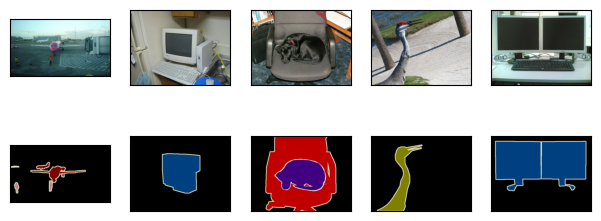

In [4]:
n = 5
imgs = train_features[:n] + train_labels[:n]
d2l.show_images(imgs, 2, n);

Next, we enumerate
the RGB color values and class names
for all the labels in this dataset.

In [5]:

VOC_COLORMAP = [[0, 0, 0], [128, 0, 0], [0, 128, 0], [128, 128, 0],
                [0, 0, 128], [128, 0, 128], [0, 128, 128], [128, 128, 128],
                [64, 0, 0], [192, 0, 0], [64, 128, 0], [192, 128, 0],
                [64, 0, 128], [192, 0, 128], [64, 128, 128], [192, 128, 128],
                [0, 64, 0], [128, 64, 0], [0, 192, 0], [128, 192, 0],
                [0, 64, 128]]


VOC_CLASSES = ['background', 'aeroplane', 'bicycle', 'bird', 'boat',
               'bottle', 'bus', 'car', 'cat', 'chair', 'cow',
               'diningtable', 'dog', 'horse', 'motorbike', 'person',
               'potted plant', 'sheep', 'sofa', 'train', 'tv/monitor']

With the two constants defined above,
we can conveniently
find the class index for each pixel in a label.
We define the `voc_colormap2label` function
to build the mapping from the above RGB color values
to class indices,
and the `voc_label_indices` function
to map any RGB values to their class indices in this Pascal VOC2012 dataset.

In [6]:

def voc_colormap2label():
    """Build the mapping from RGB to class indices for VOC labels."""
    colormap2label = np.zeros(256 ** 3, dtype=np.int32)
    for i, colormap in enumerate(VOC_COLORMAP):
        colormap2label[
            (colormap[0] * 256 + colormap[1]) * 256 + colormap[2]] = i
    return colormap2label


def voc_label_indices(colormap, colormap2label):
    """Map any RGB values in VOC labels to their class indices."""
    colormap = colormap.astype(np.int32)
    idx = ((colormap[:, :, 0] * 256 + colormap[:, :, 1]) * 256
           + colormap[:, :, 2])
    return colormap2label[idx]

For example, in the first example image,
the class index for the front part of the airplane is 1,
while the background index is 0.

In [7]:
y = voc_label_indices(train_labels[0], voc_colormap2label())
y[105:115, 130:140], VOC_CLASSES[1]

(array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0, 0, 0, 1, 1, 1],
        [0, 0, 0, 0, 0, 0, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 1, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 0, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 0, 0, 0, 1, 1]], dtype=int32),
 'aeroplane')

### Data Preprocessing

In previous experiments
such as in that section to that section,
images are rescaled
to fit the model's required input shape.
However, in semantic segmentation,
doing so
requires rescaling the predicted pixel classes
back to the original shape of the input image.
Such rescaling may be inaccurate,
especially for segmented regions with different classes. To avoid this issue,
we crop the image to a *fixed* shape instead of rescaling. Specifically, using random cropping from image augmentation, we crop the same area of
the input image and the label.

In [8]:

def voc_rand_crop(feature, label, height, width):
    """Randomly crop both feature and label images."""
    # Use NumPy for the random crop so this is safe to run from worker
    # threads (tf.image.random_crop holds graph-side state that breaks
    # under tf.data parallel py_function calls).
    H, W = feature.shape[0], feature.shape[1]
    top = int(np.random.randint(0, H - height + 1))
    left = int(np.random.randint(0, W - width + 1))
    feat = feature[top:top + height, left:left + width, :]
    lab = label[top:top + height, left:left + width, :]
    return feat, lab

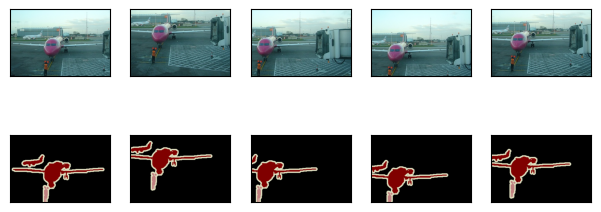

In [9]:
imgs = []
for _ in range(n):
    imgs += voc_rand_crop(train_features[0], train_labels[0], 200, 300)
d2l.show_images(imgs[::2] + imgs[1::2], 2, n);

### Custom Semantic Segmentation Dataset Class

We define a custom semantic segmentation dataset class `VOCSegDataset` by inheriting the `Dataset` class provided by high-level APIs.
By implementing the `__getitem__` function,
we can arbitrarily access the input image indexed as `idx` in the dataset and the class index of each pixel in this image.
Since some images in the dataset
have a smaller size
than the output size of random cropping,
these examples are filtered out
by a custom `filter` function.
In addition, we also
define the `normalize_image` function to
standardize the values of the three RGB channels of input images.

In [10]:

class VOCSegDataset:
    """A customized dataset to load the VOC dataset."""

    def __init__(self, is_train, crop_size, voc_dir):
        self.rgb_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.rgb_std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
        self.crop_size = crop_size
        features, labels = read_voc_images(voc_dir, is_train=is_train)
        self.features = [self.normalize_image(feature)
                         for feature in self.filter(features)]
        self.labels = self.filter(labels)
        self.colormap2label = voc_colormap2label()
        print('read ' + str(len(self.features)) + ' examples')

    def normalize_image(self, img):
        return (img.astype(np.float32) / 255 - self.rgb_mean) / self.rgb_std

    def filter(self, imgs):
        return [img for img in imgs if (
            img.shape[0] >= self.crop_size[0] and
            img.shape[1] >= self.crop_size[1])]

    def __getitem__(self, idx):
        feature, label = voc_rand_crop(self.features[idx], self.labels[idx],
                                       *self.crop_size)
        # feature: HWC float32; label: HWC uint8 RGB -> class indices HW int32
        label_idx = voc_label_indices(label, self.colormap2label)
        return (feature.astype(np.float32),
                label_idx.astype(np.int32))

    def __len__(self):
        return len(self.features)

### Reading the Dataset

We use the custom `VOCSegDataset` class to
create instances of the training set and test set, respectively.
Suppose that
we specify that the output shape of randomly cropped images is $320\times 480$.
Below we can view the number of examples
that are retained in the training set and test set.

In [11]:
crop_size = (320, 480)
voc_train = VOCSegDataset(True, crop_size, voc_dir)
voc_test = VOCSegDataset(False, crop_size, voc_dir)

read 1114 examples


read 1078 examples


Setting the batch size to 64,
we define the data iterator for the training set.
Let's print the shape of the first minibatch.
Different from in image classification or object detection, labels here are three-dimensional tensors.

In [12]:
batch_size = 64
indices = np.random.permutation(len(voc_train))
batch = [voc_train[i] for i in indices[:batch_size]]
X = tf.stack([b[0] for b in batch])
Y = tf.stack([b[1] for b in batch])
print(X.shape)
print(Y.shape)

(64, 320, 480, 3)
(64, 320, 480)


### Putting It All Together

Finally, we define the following `load_data_voc` function
to download and read the Pascal VOC2012 semantic segmentation dataset.
It returns data iterators for both the training and test datasets.

In [13]:

def load_data_voc(batch_size, crop_size):
    """Load the VOC semantic segmentation dataset."""
    voc_dir = d2l.download_extract('voc2012', os.path.join(
        'VOCdevkit', 'VOC2012'))
    train_dataset = VOCSegDataset(True, crop_size, voc_dir)
    test_dataset = VOCSegDataset(False, crop_size, voc_dir)
    n_train = len(train_dataset)
    n_test = len(test_dataset)
    # Drop last partial batch
    n_train = (n_train // batch_size) * batch_size
    n_test = (n_test // batch_size) * batch_size
    def make_tf_dataset(dataset, n, shuffle):
        # Cropping/labeling is plain NumPy; wrap in tf.py_function and run it
        # in parallel so the GPU isn't starved between batches. We use
        # from_tensor_slices(indices) + map(parallel) instead of a single
        # serial Python generator.
        feat0, label0 = dataset[0]
        feat_shape, label_shape = feat0.shape, label0.shape
        def load(i):
            feat, label = dataset[int(i)]
            return feat, label
        def tf_load(i):
            feat, label = tf.py_function(
                load, [i], (tf.float32, tf.int32))
            feat.set_shape(feat_shape)
            label.set_shape(label_shape)
            return feat, label
        ds = tf.data.Dataset.from_tensor_slices(
            np.arange(len(dataset), dtype=np.int64))
        if shuffle:
            ds = ds.shuffle(buffer_size=min(n, 1000),
                            reshuffle_each_iteration=True)
        ds = ds.take(n)
        ds = ds.map(tf_load, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.batch(batch_size, drop_remainder=True)
        ds = ds.prefetch(tf.data.AUTOTUNE)
        return ds
    train_iter = make_tf_dataset(train_dataset, n_train, shuffle=True)
    test_iter = make_tf_dataset(test_dataset, n_test, shuffle=False)
    return train_iter, test_iter

## Summary

* Semantic segmentation recognizes and understands what are in an image in pixel level by dividing the image into regions belonging to different semantic classes.
* One of the most important semantic segmentation dataset is Pascal VOC2012.
* In semantic segmentation, since the input image and  label correspond one-to-one on the pixel, the input image is randomly cropped to a fixed shape rather than rescaled.


## Exercises

1. How can semantic segmentation be applied in autonomous vehicles and medical image diagnostics? Can you think of other applications?
1. Recall the descriptions of data augmentation in that section. Which of the image augmentation methods used in image classification would be infeasible to be applied in semantic segmentation?
1. Use `voc_label_indices` to compute, over all training labels returned by `read_voc_images`, the fraction of pixels in each of the 21 classes and the number of images in which each class occurs. Report the background fraction and the class with the fewest pixels. Which pixel accuracy does a model attain that predicts background everywhere? The intersection over union (IoU) of class $c$ is the number of pixels both predicted and labeled as $c$, divided by the number predicted or labeled as $c$. Compute this model's IoU for every class and the mean over the 21 classes, and explain why the mean IoU separates this model from a useful one while the pixel accuracy does not.
1. The text crops images instead of rescaling them because rescaling a label image is inaccurate.
    1. Two neighboring label pixels belong to the classes cat (index 8) and dog (index 12). Interpolating the class indices linearly halfway between them gives which index, and which class does it name? Interpolating their colors from `VOC_COLORMAP` instead gives which color, and which index does `voc_label_indices` return for it?
    1. Implement a random-scale augmentation that resizes the input image with bilinear interpolation and the label image with nearest-neighbor interpolation, by a common factor drawn uniformly from $[1, 2]$, before calling `voc_rand_crop`. Check that every pixel of the resulting labels has a color in `VOC_COLORMAP`, and count the pixels that fail this check when the label image is resized with bilinear interpolation instead.
1. In the label images, object borders and regions that are hard to label are drawn in the color $(224, 224, 192)$, which is not in `VOC_COLORMAP`.
    1. From the way `voc_colormap2label` builds its lookup table, determine the class index that `voc_label_indices` assigns to these pixels. Compute the fraction of such pixels in the training labels.
    1. Change `voc_colormap2label` so that this color maps to the index 255, and state how the per-pixel cross-entropy loss and the pixel accuracy must treat pixels with this index.
    1. With such an index available, `VOCSegDataset` no longer needs to discard the training images that are smaller than `crop_size`. Modify it to pad the image and the label instead, state the label value of the padded pixels, and report the number of training examples the dataset then contains for `crop_size = (320, 480)`.

[Discussions](https://d2l.discourse.group/t/1480)